In [1]:
import json
import numpy as np
import pandas as pd
from functools import reduce

import mysql.connector
from mysql.connector import MySQLConnection

import larch
from larch.roles import P,X

import pyarrow as pa
import pyarrow.feather as feather

## Load data

In [2]:
credentials = {
  "user": "external.data.user",
  "password": "wIfQxcjgZ5!gA*FWgi1z$Kj9",
  "host": "35.208.148.42",
  "port": 3306
}

conn: MySQLConnection = mysql.connector.connect(**credentials)

In [3]:
def get_dms_data(conn: MySQLConnection, guid: str):
    cur = conn.cursor()
    query = """
    SELECT DATA FROM external_data.dms WHERE guid = %s
    """

    cur.execute(query, [guid])
    columns = cur.description
    rows = [{columns[index][0]: column for index, column in enumerate(value)} for value in cur.fetchall()]
    cur.close()
    
    return dict(rows[0])['DATA']

def get_dms_data_to_json(conn: MySQLConnection, guid: str):
    return json.loads(get_dms_data(conn, guid))

def get_dms_data_to_df(conn: MySQLConnection, guid: str):
    return feather.read_feather(pa.BufferReader(get_dms_data(conn, guid)))

In [4]:
guid_info = "7c0eea07-99a1-458e-a315-2b67cc9981ad"
guid_topics_dcm = "2ecf3ce4-aede-4516-a049-5d274659e5ec"
guid_genres_dcm = "4a30eb82-dc77-47c0-99ab-98d4ffb9759f"
guid_tags = "73df38cd-31aa-43e5-b05b-6e973ab35295"

In [5]:
info_df = get_dms_data_to_df(conn, guid_info)
topic_dcm_df = get_dms_data_to_df(conn, guid_topics_dcm)
genres_dcm_df = get_dms_data_to_df(conn, guid_genres_dcm)
tags_df = get_dms_data_to_df(conn, guid_tags)

In [6]:
conn.close()

In [7]:
# user metadata1 - age, gender, spend, playtime, loyalty
info_df

,id,survey_meta_id,survey_instance,age,gender,role,favorite_game,spending,playing_time,loyalty
0,1,1,33cbe449-af6a-484b-a521-6a4d08f73454,37,f,10,com.my.defense,75,15,5
1,2,1,5db16995-594b-4b4e-9151-e502b85d6ff3,42,m,10,com.scopely.monopolygo,5,13,4
2,3,1,9722c487-9a13-4a9d-8599-577b69805034,42,f,10,com.dreamgames.royalmatch,5,0,1
3,4,1,7094ec2f-88d4-4642-90f6-f12b41eca4f1,65,m,10,com.samfinaco.paradise,300,15,5
4,5,1,eb6a4d45-c680-4eaf-bef7-aebe5edb7ce0,37,m,10,com.riotgames.league.teamfighttactics,300,8,4
...,...,...,...,...,...,...,...,...,...,...
1965,1966,1,35fc0bbf-cef7-4ad9-b0c7-8bfb50043cc3,32,m,10,com.miniclip.eightballpool,15,8,4
1966,1967,1,b11b6d9c-f739-478a-ab26-d26d11825827,32,m,10,com.nintendo.zara,0,8,1
1967,1968,1,e9c3e858-826f-479e-a85d-6ea3b0e4e43a,32,m,10,com.playtika.wsop.gp,15,8,-1
1968,1969,1,b6e5ec83-0b04-4f2d-8d54-1bc0d6785adc,32,m,4,com.bandainamcogames.dbzdokkanww,0,0,1


In [8]:
# topic - environment + eras / domain + focus / entity / role conjoint
topic_dcm_df

,id,survey_meta_id,survey_instance,dcm_order,topic,feature_1a,feature_1b,feature_2a,feature_2b,chosen_a,chosen_b
0,1,1,33cbe449-af6a-484b-a521-6a4d08f73454,1,topics__fantasy,entities__robot,roles__creator,entities__celestial,roles__team,None,None
1,2,1,33cbe449-af6a-484b-a521-6a4d08f73454,2,topics__fantasy,entities__kid,roles__carer,entities__animal,roles__warrior,None,None
2,3,1,33cbe449-af6a-484b-a521-6a4d08f73454,3,topics__fantasy,environment__aquatic,domains__crime,environment__alternality,domains__business,environment__aquatic,domains__crime
3,4,1,33cbe449-af6a-484b-a521-6a4d08f73454,4,topics__fantasy,entities__adult,roles__rebel,entities__zombie,roles__creator,entities__zombie,roles__creator
4,5,1,33cbe449-af6a-484b-a521-6a4d08f73454,5,topics__fantasy,environment__wilderness,focus__weapons,environment__space,domains__military,None,None
...,...,...,...,...,...,...,...,...,...,...,...
6985,6986,1,8ec75988-2510-4d41-b5da-456e237c2574,1,topics__mystery,entities__celestial,roles__mystic,entities__plant,roles__follower,entities__plant,roles__follower
6986,6987,1,8ec75988-2510-4d41-b5da-456e237c2574,2,topics__mystery,entities__super_,roles__warrior,entities__celestial,roles__creator,entities__super_,roles__warrior
6987,6988,1,8ec75988-2510-4d41-b5da-456e237c2574,3,topics__mystery,entities__human,roles__team,entities__robot,roles__carer,entities__human,roles__team
6988,6989,1,8ec75988-2510-4d41-b5da-456e237c2574,4,topics__mystery,entities__alien,roles__solver,entities__celestial,roles__mystic,entities__alien,roles__solver


In [9]:
# genres - mechanics conjoint
genres_dcm_df

,id,survey_meta_id,survey_instance,dcm_order,genre_1,genre_2,core_1,core_2,chosen
0,1,1,33cbe449-af6a-484b-a521-6a4d08f73454,1,genre__match,None,core__connect,core__merge,core__merge
1,2,1,33cbe449-af6a-484b-a521-6a4d08f73454,2,genre__casino,None,core__slots,core__poker,core__slots
2,3,1,33cbe449-af6a-484b-a521-6a4d08f73454,3,genre__strategy,None,core__4x,core__lane,core__lane
3,4,1,33cbe449-af6a-484b-a521-6a4d08f73454,4,genre__strategy,genre__match,core__lane,core__blast,core__blast
4,5,1,33cbe449-af6a-484b-a521-6a4d08f73454,5,genre__match,genre__strategy,core__merge,core__summon,core__summon
...,...,...,...,...,...,...,...,...,...
8940,8941,1,8ec75988-2510-4d41-b5da-456e237c2574,1,genre__combat,genre__education,core__moba,core__asymetric,core__moba
8941,8942,1,8ec75988-2510-4d41-b5da-456e237c2574,2,genre__education,genre__combat,core__vehicular,core__bullet_hell,core__bullet_hell
8942,8943,1,8ec75988-2510-4d41-b5da-456e237c2574,3,genre__puzzle,genre__casino,core__time_loop,core__poker,core__time_loop
8943,8944,1,8ec75988-2510-4d41-b5da-456e237c2574,4,genre__puzzle,genre__education,core__escape_room,core__move_blocks,core__escape_room


In [10]:
# user metadata 2 - platforms, genres, topics, needs, behaviours, activities, movies, hobbies, socials
tags_df

,id,survey_meta_id,tag_id,tag_value,survey_instance
0,1,1,platforms__mobile,1,33cbe449-af6a-484b-a521-6a4d08f73454
1,2,1,platforms__playstation,1,33cbe449-af6a-484b-a521-6a4d08f73454
2,3,1,platforms__pc,1,33cbe449-af6a-484b-a521-6a4d08f73454
3,4,1,genre__rpg,66,33cbe449-af6a-484b-a521-6a4d08f73454
4,5,1,genre__match,100,33cbe449-af6a-484b-a521-6a4d08f73454
...,...,...,...,...,...
121361,121362,1,multiplayer__multi,4,8ec75988-2510-4d41-b5da-456e237c2574
121362,121363,1,multiplayer__single,3,8ec75988-2510-4d41-b5da-456e237c2574
121363,121364,1,activities__working,1,8ec75988-2510-4d41-b5da-456e237c2574
121364,121365,1,activities__parenting,1,8ec75988-2510-4d41-b5da-456e237c2574


In [11]:
tags_pivot_df = tags_df.pivot(
    index="survey_instance", columns="tag_id", values="tag_value"
).reset_index()

tags_pivot_df.columns.name = None

sorted_categories = ['platforms', 'multiplayer', 'genre', 'topics', 'needs', 'behaviors', 'activities', 'movies', 'hobbies', 'socials']
sorted_col_names = sorted(tags_df.tag_id.unique(), key=lambda x: f"{sorted_categories.index(x.split('_')[0])}_{'_'.join(x.split('_')[2:])}")

tags_pivot_df = tags_pivot_df[['survey_instance'] + sorted_col_names]
tags_pivot_df

,survey_instance,platforms__mobile,platforms__pc,platforms__playstation,platforms__switch,platforms__xbox,multiplayer__multi,multiplayer__single,genre__arcade,genre__building,...,socials__linkedin,socials__pinterest,socials__reddit,socials__snapchat,socials__telegram,socials__tiktok,socials__twitch,socials__twitter,socials__whatsapp,socials__youtube
0,000e7770-bcb0-494f-87b1-ff31f975c98d,1.0,NaN,NaN,NaN,NaN,4.0,4.0,33.0,NaN,...,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0027a589-c6bf-480d-8e12-77cf79b45152,1.0,NaN,NaN,NaN,NaN,1.0,4.0,100.0,NaN,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN,NaN,NaN
2,003d6fa0-2ce5-4eba-9053-5f0bc832d6ff,1.0,1.0,1.0,1.0,NaN,3.0,4.0,100.0,100.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,004d89f9-a2ce-4777-b32a-3e111edb5d44,1.0,NaN,NaN,NaN,1.0,3.0,4.0,33.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,005f6277-0f98-417c-86d7-9462a8780587,1.0,NaN,1.0,NaN,1.0,4.0,4.0,100.0,33.0,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1965,ffc684b4-4c08-41c2-9c13-22700afecc6b,1.0,NaN,1.0,NaN,NaN,3.0,4.0,66.0,33.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1966,ffedffd2-21c5-449e-9396-4991f62ca880,1.0,1.0,1.0,NaN,NaN,2.0,4.0,33.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1967,fff0cf1d-11dd-4819-a104-a12051e64a2f,1.0,NaN,1.0,1.0,NaN,3.0,4.0,66.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1968,fff7e72f-0682-4d36-9690-6d8f95466e6a,1.0,1.0,NaN,NaN,1.0,4.0,4.0,66.0,100.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
sorted_col_names

['platforms__mobile',
 'platforms__pc',
 'platforms__playstation',
 'platforms__switch',
 'platforms__xbox',
 'multiplayer__multi',
 'multiplayer__single',
 'genre__arcade',
 'genre__building',
 'genre__casino',
 'genre__combat',
 'genre__driving',
 'genre__education',
 'genre__idle',
 'genre__match',
 'genre__party',
 'genre__puzzle',
 'genre__rpg',
 'genre__simulation',
 'genre__sports',
 'genre__story',
 'genre__strategy',
 'genre__tabletop',
 'topics__action',
 'topics__adventure',
 'topics__comedy',
 'topics__drama',
 'topics__fantasy',
 'topics__horror',
 'topics__mystery',
 'topics__realistic',
 'topics__romance',
 'topics__sci_fi',
 'needs__acceptance',
 'needs__accomplishment',
 'needs__appreciation',
 'needs__control',
 'needs__fitness',
 'needs__insight',
 'needs__intimacy',
 'needs__mastery',
 'needs__morality',
 'needs__novelty',
 'needs__recognition',
 'needs__relief',
 'needs__safety',
 'needs__superiority',
 'needs__trust',
 'needs__uniqueness',
 'needs__wealth',
 'beha

In [13]:
PLATFORM_COLS = ['platforms__mobile', 'platforms__pc', 'platforms__playstation', 'platforms__switch', 'platforms__xbox']
MULTIPLAYER_COLS = ['multiplayer__multi', 'multiplayer__single']
GENRE_COLS = [
    'genre__arcade', 'genre__building', 'genre__casino', 'genre__combat', 'genre__driving',
    'genre__education', 'genre__idle', 'genre__match', 'genre__party', 'genre__puzzle',
    'genre__rpg', 'genre__simulation', 'genre__sports', 'genre__story', 'genre__strategy',
    'genre__tabletop',
]
TOPIC_COLS = [
    'topics__action', 'topics__adventure', 'topics__comedy', 'topics__drama', 'topics__fantasy',
    'topics__horror', 'topics__mystery', 'topics__realistic', 'topics__romance', 'topics__sci_fi',
]
NEED_COLS = [
    'needs__acceptance', 'needs__accomplishment', 'needs__appreciation', 'needs__control',
    'needs__fitness', 'needs__insight', 'needs__intimacy', 'needs__mastery', 'needs__morality',
    'needs__novelty', 'needs__recognition', 'needs__relief', 'needs__safety', 'needs__superiority',
    'needs__trust', 'needs__uniqueness', 'needs__wealth',
]
BEHAVIOUR_COLS = [
    'behaviors__chill', 'behaviors__collect', 'behaviors__combat', 'behaviors__compete',
    'behaviors__complete', 'behaviors__cooperate', 'behaviors__destroy', 'behaviors__discover',
    'behaviors__empower', 'behaviors__experiment', 'behaviors__express', 'behaviors__immerse',
    'behaviors__plan', 'behaviors__react', 'behaviors__solve',
]
ACTIVITY_COLS = [
    'activities__following_news', 'activities__friends', 'activities__hobbies', 'activities__learning',
    'activities__movies', 'activities__music', 'activities__parenting', 'activities__partner',
    'activities__pets', 'activities__reading', 'activities__social_media', 'activities__video_games',
    'activities__working',
]
MOVIE_COLS = [
    'movies__action_adventure', 'movies__anime', 'movies__children_family', 'movies__classic',
    'movies__comedies', 'movies__criminal', 'movies__documentary', 'movies__drama', 'movies__fantasy',
    'movies__horror', 'movies__reality_shows', 'movies__romantic', 'movies__scifi',
]
HOBBY_COLS = [
    'hobbies__building_fixing', 'hobbies__collecting', 'hobbies__cooking', 'hobbies__design',
    'hobbies__diy', 'hobbies__driving', 'hobbies__exercising_sports', 'hobbies__farm_garden',
    'hobbies__fishing_hunting', 'hobbies__gardening', 'hobbies__performing_arts', 'hobbies__photographing',
    'hobbies__serving_community', 'hobbies__teaching', 'hobbies__watching_games', 'hobbies__watching_sports',
]
SOCIAL_COLS = [
    'socials__discord', 'socials__facebook', 'socials__instagram', 'socials__linkedin', 'socials__pinterest',
    'socials__reddit', 'socials__snapchat', 'socials__telegram', 'socials__tiktok', 'socials__twitch',
    'socials__twitter', 'socials__whatsapp', 'socials__youtube',
]

In [79]:
user_df = info_df.merge(tags_pivot_df, on='survey_instance')

In [80]:
user_df

,id,survey_meta_id,survey_instance,age,gender,role,favorite_game,spending,playing_time,loyalty,...,socials__linkedin,socials__pinterest,socials__reddit,socials__snapchat,socials__telegram,socials__tiktok,socials__twitch,socials__twitter,socials__whatsapp,socials__youtube
0,1,1,33cbe449-af6a-484b-a521-6a4d08f73454,37,f,10,com.my.defense,75,15,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,1,5db16995-594b-4b4e-9151-e502b85d6ff3,42,m,10,com.scopely.monopolygo,5,13,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,1,9722c487-9a13-4a9d-8599-577b69805034,42,f,10,com.dreamgames.royalmatch,5,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,1,7094ec2f-88d4-4642-90f6-f12b41eca4f1,65,m,10,com.samfinaco.paradise,300,15,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,1,eb6a4d45-c680-4eaf-bef7-aebe5edb7ce0,37,m,10,com.riotgames.league.teamfighttactics,300,8,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1965,1966,1,35fc0bbf-cef7-4ad9-b0c7-8bfb50043cc3,32,m,10,com.miniclip.eightballpool,15,8,4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1966,1967,1,b11b6d9c-f739-478a-ab26-d26d11825827,32,m,10,com.nintendo.zara,0,8,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0
1967,1968,1,e9c3e858-826f-479e-a85d-6ea3b0e4e43a,32,m,10,com.playtika.wsop.gp,15,8,-1,...,NaN,NaN,1.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN
1968,1969,1,b6e5ec83-0b04-4f2d-8d54-1bc0d6785adc,32,m,4,com.bandainamcogames.dbzdokkanww,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Dataframe selection

In [229]:
# dataset = 'US'

# panel_dfs[dataset] = panel_df
# dcm_dfs[dataset] = dcm_df

In [230]:
# dataset = 'US'
# dataset = 'DE'

# panel_df = panel_dfs[dataset]
# dcm_df = dcm_dfs[dataset]

## Dataframe preparation

In [231]:
user_id = 'guid'
options_col = 'card_num'
theme_col = 't'
choice_col = 'score'

In [232]:
options_shown = dcm_df[options_col].value_counts().to_list()

if options_shown[0] != options_shown[-1]:
    print('ToDo - implement variable amount of options')

options = options_shown[0]

In [233]:
dcm_feature_cols = sorted(list(set(['f' + x['group'] for x in definitions['dcm_features']])))

In [234]:
dcm_df2 = dcm_df.copy()

dcm_df2['t'] = dcm_df2.t.apply(lambda x: x if x != 'none' else ' none')
dcm_df2 = dcm_df2.sort_values(["card_num", "t"], ascending=False)

In [235]:
dcm_df2[dcm_df2.score == 100].t.value_counts()

nord     1610
olymp    1548
slav     1364
china    1205
 none     793
Name: t, dtype: int64

### Shared params prep

In [236]:
dcm_cols=[]

for i in range(options - 1):
    option_df = dcm_df2[i::options]
    
    for t_dict in definitions['dcm_title']:
        if t_dict['is_none'] == '1':
            continue
        
        t_df = option_df[option_df[theme_col] == t_dict['id']]
        t_df.index = t_df.card_num

        col_index = t_df.index.drop_duplicates()
        new_col = pd.Series(data=[1]*len(col_index), index=col_index, name=f'op{i}_{t_dict["id"]}')

        dcm_cols.append(new_col)

        for f_dict in definitions['dcm_features']:
            new_col = t_df[t_df[f'f{f_dict["group"]}'] == f_dict['id']][f'f{f_dict["group"]}'].apply(lambda x: 1)
            new_col.name = f'op{i}_{t_dict["id"]}_{f_dict["id"]}'

            dcm_cols.append(new_col)

score_cols = []            

for i in range(options):
    score_cols.append(dcm_df2[choice_col][i::options].apply(lambda x: [x]).reset_index(drop=True))
    
score_col = reduce(lambda x, y: x + y, score_cols).apply(lambda x: x.index(100))
score_col.index = dcm_df2[options_col][::options]
score_col.name = 'choice'

dcm_cols.append(score_col)

In [237]:
dcm_co_df = pd.concat(dcm_cols, axis=1)
dcm_co_df = dcm_co_df.fillna(0).merge(dcm_df[[user_id, options_col]].drop_duplicates(), on=options_col)

In [238]:
for i in range(options):
    dcm_co_df[f'av{i}'] = 1

In [239]:
# ToDo combine with panel data

In [240]:
dcm_co_df = dcm_co_df.merge(panel_df, on='guid')

In [241]:
panel_df.columns.to_list()

['guid',
 'cint_id',
 'time',
 'age',
 'age_url',
 'gender',
 'gender_url',
 'spending',
 'genres__rpg',
 'genres__story',
 'genres__puzzle',
 'genres__strategy',
 'genres__survival',
 'genres__action',
 'genres_sub__rpg__history',
 'genres_sub__rpg__fantasy',
 'genres_sub__rpg__scifi',
 'genres_sub__rpg__survival',
 'genres_sub__rpg__action',
 'genres_sub__story__noir',
 'genres_sub__story__fantasy',
 'genres_sub__story__scifi',
 'genres_sub__story__mystery',
 'genres_sub__story__romance',
 'genres_sub__puzzle__hidden',
 'genres_sub__puzzle__action',
 'genres_sub__puzzle__environment',
 'genres_sub__strategy__realtime',
 'genres_sub__strategy__turnbased',
 'genres_sub__strategy__hybrid',
 'genres_sub__survival__action',
 'genres_sub__survival__exploration',
 'genres_sub__survival__strategy',
 'genres_sub__survival__sandbox',
 'genres_sub__survival__horror',
 'genres_sub__action__shooter',
 'genres_sub__action__adventure',
 'genres_sub__action__stealth',
 'genres_sub__action__souls',
 

In [242]:
combine_with_topic_categories = [
    'genres', 'behaviors',
]

dcm_cols2 = []

for i in range(options - 1):
    for t_dict in definitions['dcm_title']:
        if t_dict['is_none'] == '1':
            continue
        
        for category in combine_with_topic_categories:
            for col_dict in definitions[category]:
                col = f'{category}__{col_dict["id"]}'
                
                new_col = dcm_co_df[f'op{i}_{t_dict["id"]}'] * dcm_co_df[col]
                new_col.name = f'op{i}_{t_dict["id"]}_{col}'
                
                dcm_cols2.append(new_col)
        
#         t_df = option_df[option_df[theme_col] == t_dict['id']]
#         t_df.index = t_df.card_num

#         col_index = t_df.index.drop_duplicates()
#         new_col = pd.Series(data=[1]*len(col_index), index=col_index, name=f'op{i}_{t_dict["id"]}')

#         dcm_cols.append(new_col)

#         for f_dict in definitions['dcm_features']:
#             new_col = t_df[t_df[f'f{f_dict["group"]}'] == f_dict['id']][f'f{f_dict["group"]}'].apply(lambda x: 1)
#             new_col.name = f'op{i}_{t_dict["id"]}_{f_dict["id"]}'

#             dcm_cols.append(new_col)


In [243]:
dcm_co_df = pd.concat([dcm_co_df] + dcm_cols2, axis=1)

### Theme based prep

In [244]:
temp_dfs = []

for i in range(options - 1):
    temp_dfs.append(dcm_df2[i::options])
    
temp_df = pd.concat(temp_dfs)

themes_lists = reduce(lambda x, y: x + y, [x[theme_col].apply(lambda x: [x]).set_axis(x[options_col]) for x in temp_dfs])
duplicate_themes = themes_lists.apply(lambda x: len(set(x))) == (options - 1)

# Remove options with repeating topics
temp_df = temp_df[temp_df[options_col].isin(duplicate_themes[duplicate_themes].index)]

dcm_cols=[]

for t_dict in definitions['dcm_title']:
    if t_dict['is_none'] == '1':
        continue

    t_df = temp_df[temp_df[theme_col] == t_dict['id']]
    t_df.index = t_df.card_num

    col_index = t_df.index.drop_duplicates()
    new_col = pd.Series(data=[1]*len(col_index), index=col_index, name=f'{t_dict["id"]}_av')

    dcm_cols.append(new_col)

    for f_dict in definitions['dcm_features']:
        new_col = t_df[t_df[f'f{f_dict["group"]}'] == f_dict['id']][f'f{f_dict["group"]}'].apply(lambda x: 1)
        new_col.name = f'{t_dict["id"]}_{f_dict["id"]}'

        dcm_cols.append(new_col)

score_cols = []

for i in range(options):
    score_cols.append(dcm_df2[choice_col][i::options].apply(lambda x: [x]).reset_index(drop=True))
    
score_col = reduce(lambda x, y: x + y, score_cols).apply(lambda x: x.index(100))
score_col.index = dcm_df2[options_col][::options]
score_col.name = 'choice'

score_col_theme = pd.concat([themes_lists.apply(lambda x: x + ['none']), score_col], axis=1).apply(lambda x: x['t'][x['choice']], axis=1)
score_col_theme = score_col_theme[duplicate_themes[duplicate_themes].index]
score_col_theme.name = 'choice'

theme_mapping = {t_dict['id']: idx for idx, t_dict in enumerate(definitions['dcm_title'])}
score_col_theme = score_col_theme.apply(lambda x: theme_mapping[x])

none_av = pd.Series([1] * len(score_col_theme), score_col_theme.index, name='none_av')

dcm_cols.append(score_col_theme)
dcm_cols.append(none_av)

In [245]:
dcm_co_df2 = pd.concat(dcm_cols, axis=1)
dcm_co_df2 = dcm_co_df2.fillna(0).merge(dcm_df[[user_id, options_col]].drop_duplicates(), on=options_col)

In [246]:
dcm_co_df2 = dcm_co_df2.merge(panel_df, on='guid')

In [247]:
combine_with_topic_categories = [
    'genres', 'behaviors',
]

dcm_cols2 = []

for t_dict in definitions['dcm_title']:
    if t_dict['is_none'] == '1':
        continue

    for category in combine_with_topic_categories:
        for col_dict in definitions[category]:
            col = f'{category}__{col_dict["id"]}'

            new_col = dcm_co_df2[f'{t_dict["id"]}_av'] * dcm_co_df2[col]
            new_col.name = f'{t_dict["id"]}_{col}'

            dcm_cols2.append(new_col)

In [248]:
dcm_co_df2 = pd.concat([dcm_co_df2] + dcm_cols2, axis=1)

## Modelling

In [249]:
m = larch.Model()

In [250]:
m.choice_co_code = 'choice'

In [251]:
dcm_type = 'topic_based' # shared, topic_based

In [252]:
if dcm_type == 'topic_based':
    m.availability_co_vars = {idx: f'{t_dict["id"]}_av' for idx, t_dict in enumerate(definitions['dcm_title'])}

    for idx, t_dict in enumerate(definitions['dcm_title']):
        if t_dict['is_none'] == '1':
            m.utility_co[idx] = 0
        else:
            m.utility_co[idx] = P(f'{t_dict["id"]}_ASC')
            for col in [x for x in dcm_co_df2.columns if f'{t_dict["id"]}_' in x and x != f'{t_dict["id"]}_av']:
                m.utility_co[idx] += X(col) * P(col)

    dfs = larch.DataFrames(dcm_co_df2, alt_codes=[i for i in range(len(definitions['dcm_title']))])
    
elif dcm_type == 'shared':
    m.availability_co_vars = {i: f'av{i}' for i in range(options)}

    for i in range(options - 1):
        for col in [x for x in dcm_co_df.columns if x[:3] == f'op{i}']:
            m.utility_co[i] += X(col) * P(col[4:])

    m.utility_co[options - 1] = 0

    dfs = larch.DataFrames(dcm_co_df, alt_codes=[i for i in range(options)])

In [253]:
m.dataservice = dfs

In [254]:
m.load_data()

C:\Users\daide\AppData\Local\Temp/ipykernel_18336/1940460508.py:1: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  m.load_data()


In [255]:
m.maximize_loglike(quiet=False)

,value,initvalue,nullvalue,minimum,maximum,holdfast,note,best
china_1,-0.606038,0.0,0.0,-inf,inf,0,,-0.606038
china_10,-0.216430,0.0,0.0,-inf,inf,0,,-0.216430
china_11,-0.013798,0.0,0.0,-inf,inf,0,,-0.013798
china_12,-0.218679,0.0,0.0,-inf,inf,0,,-0.218679
china_13,-0.297436,0.0,0.0,-inf,inf,0,,-0.297436
...,...,...,...,...,...,...,...,...
slav_genres__puzzle,0.713040,0.0,0.0,-inf,inf,0,,0.713040
slav_genres__rpg,0.770567,0.0,0.0,-inf,inf,0,,0.770567
slav_genres__story,1.390721,0.0,0.0,-inf,inf,0,,1.390721
slav_genres__strategy,0.924334,0.0,0.0,-inf,inf,0,,0.924334


c:\programs\miniconda\lib\site-packages\larch\linalg\__init__.py:18: UserWarning: minimum eig 1.8766077248674074e-15 in general_inverse
  warnings.warn(f"minimum eig {min_eig} in general_inverse")
c:\programs\miniconda\lib\site-packages\larch\linalg\__init__.py:18: UserWarning: minimum eig 1.999745709165646e-15 in general_inverse
  warnings.warn(f"minimum eig {min_eig} in general_inverse")
c:\programs\miniconda\lib\site-packages\larch\linalg\__init__.py:18: UserWarning: minimum eig 1.3531178567100392e-15 in general_inverse
  warnings.warn(f"minimum eig {min_eig} in general_inverse")
c:\programs\miniconda\lib\site-packages\larch\linalg\__init__.py:18: UserWarning: minimum eig 5.0901508899558395e-15 in general_inverse
  warnings.warn(f"minimum eig {min_eig} in general_inverse")
c:\programs\miniconda\lib\site-packages\larch\linalg\__init__.py:18: UserWarning: minimum eig 1.1110316528699179e-14 in general_inverse
  warnings.warn(f"minimum eig {min_eig} in general_inverse")
c:\programs\mini

┣          loglike: -4222.00160749275
┣                x: china_1                 -0.606038
┃                   china_10                -0.216430
┃                   china_11                -0.013798
┃                   china_12                -0.218679
┃                   china_13                -0.297436
┃                                              ...   
┃                   slav_genres__puzzle      0.713040
┃                   slav_genres__rpg         0.770567
┃                   slav_genres__story       1.390721
┃                   slav_genres__strategy    0.924334
┃                   slav_genres__survival    1.135219
┃                   Length: 184, dtype: float64
┣        tolerance: 7.77224545929369e-06
┣            steps: array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
┃                          1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
┃                          1., 1., 1., 1., 1., 1.])
┣          message: 'Optimization terminated successfully.'
┣     elapsed_time: datetime.timedelta(seconds=2, microseconds=757519)
┣           method: 'bhhh'
┣          n_cases: 4832
┣ iteration_number: 40
┣          logloss: 0.8737586108221751

## Create probabilities

In [256]:
results = m.pfo().value

In [257]:
av_vars = m.availability_co_vars

In [258]:
def calculate_utilities_shared(utility_co, results, df, options):
    all_utilities = []
    
    for option in range(options):
        option_utilities = np.zeros(len(df))
        
        for utility_func in utility_co[option]:
            option_utilities += df[utility_func.data] * results[utility_func.param]
            
        all_utilities.append(option_utilities)
    
    return all_utilities


def calculate_utilities_topic_based(utility_co, results, df, availability_vars, options, theme_mapping):
    all_utilities = []
    all_themes = []
    
    for t_dict in definitions['dcm_title']:
        theme_utilities = np.zeros(len(df))
        
        for utility_func in utility_co[theme_mapping[t_dict['id']]]:
            if utility_func.data != '1':
                theme_utilities += df[utility_func.data] * results[utility_func.param]
            else:
                theme_utilities += results[utility_func.param]
            
        theme_utilities = (theme_utilities * df[availability_vars[theme_mapping[t_dict['id']]]].apply(lambda x: np.nan if x == 0 else 1)).apply(lambda x: [x] if not pd.isna(x) else [])
        themes = df[availability_vars[theme_mapping[t_dict['id']]]].apply(lambda x: [] if x == 0 else [t_dict['id']])
            
        all_utilities.append(theme_utilities)
        all_themes.append(themes)
        
    combined_utilities = reduce(lambda x, y: x + y, all_utilities)
    combined_themes = reduce(lambda x, y: x + y, all_themes)
    
    split_utilities = []
    split_themes = []
    for option in range(options):
        split_utilities.append(combined_utilities.apply(lambda x: x[option]))
        split_themes.append(combined_themes.apply(lambda x: x[option]))
    
    return split_utilities, split_themes


def utility_to_proba(all_utilities, scale=1):
    all_probabilities = []
    
    for i in range(len(all_utilities)):
        all_probabilities.append(np.power(np.e, all_utilities[i] * scale) / reduce(lambda x, y: x + y, map(lambda x: np.power(np.e, x * scale), all_utilities)))
    
    return all_probabilities

In [259]:
if dcm_type == 'shared':
    option_themes = []

    for i in range(options - 1):
        option_themes.append(dcm_df2[i::options][theme_col].reset_index(drop=True))
    
    probabilities = utility_to_proba(calculate_utilities(m.utility_co, results, dcm_co_df, options))

    probabilities_without_none = []

    for i in range(options - 1):
        probabilities_without_none.append(probabilities[i])

    theme_probabilities = pd.concat([pd.concat(option_themes, ignore_index=True), pd.concat(probabilities_without_none, ignore_index=True)], axis=1)
    theme_probabilities = theme_probabilities.rename(columns={0:'proba'})
    
elif dcm_type == 'topic_based':
    utilities, themes = calculate_utilities_topic_based(m.utility_co, results, dcm_co_df2, m.availability_co_vars, options, theme_mapping)
    probabilities = utility_to_proba(utilities)

    theme_probabilities = pd.concat([pd.concat(themes, ignore_index=True), pd.concat(probabilities, ignore_index=True)], axis=1)
    theme_probabilities = theme_probabilities.rename(columns={0: 't', 1:'proba'})

In [260]:
theme_probabilities

,t,proba
0,none,0.065119
1,none,0.076323
2,none,0.059308
3,none,0.069253
4,none,0.078826
...,...,...
14491,china,0.382467
14492,china,0.288297
14493,china,0.370207
14494,china,0.238010


In [261]:
theme_probabilities.groupby(theme_col).mean().sort_values('proba', ascending=False)

,proba
t,
nord,0.515090
olymp,0.463284
slav,0.420243
china,0.366151
none,0.116514


<AxesSubplot:title={'center':'proba'}, xlabel='t'>

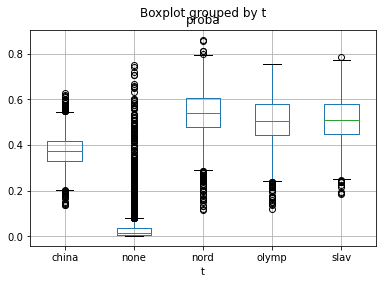

In [221]:
theme_probabilities.boxplot('proba', by='t')

In [105]:
theme_probabilities.groupby(theme_col).mean().sort_values('proba', ascending=False)

,proba
t,
slav,0.509713
olymp,0.492240
nord,0.473892
china,0.451895


<AxesSubplot:title={'center':'proba'}, xlabel='t'>

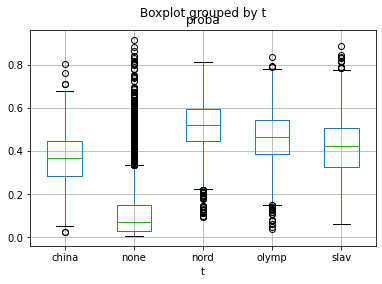

In [262]:
theme_probabilities.boxplot('proba', by='t')